# P08 — Clusterização do objeto principal com a integração escolhida no P07

Objeto principal: `dataReseq/P05_integracao/reseq_raw_integrado__v2.h5ad`,
com 35.247 células — padrão de 200 UMIs, contagens corrigidas pelo SoupX,
sem doublets (P01–P05). A integração vem do benchmark do P07
(`dataReseq/P07_benchmark_integracao/integracao_escolhida.h5ad`): o
embedding, o grafo de 15 vizinhos e a UMAP do método escolhido pelas
métricas do scIB, unidos ao objeto principal por `cell_key`.

Este notebook fecha a clusterização, **sem anotar**:

* quanto a integração escolhida misturou as bibliotecas e os pacientes, e
  quanto aproximou o estimulado do não estimulado do mesmo paciente;
* que resolução do Leiden os dados sustentam (estabilidade entre sementes);
* que clusters são técnicos (baixa profundidade, não-T);
* composição por paciente, profundidade, citocinas e estímulo por cluster.

Os rótulos de cluster vão para um arquivo à parte
(`dataReseq/P08_clusterizacao/clusters.parquet`, chave `cell_key`), sem
criar outra versão do objeto principal.

Limite de inferência: 7 pacientes, 14 bibliotecas; MB e NP com um paciente
cada. Só o contraste pareado estimulado × não estimulado (n = 7) é testado, e
de forma exploratória.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import itertools
import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy import stats

from functions import config, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P08_clusterizacao"
log = IssueLog(NB)
LIBS = config.LIBRARIES
PATS = config.PATIENTS
INK = plotting.INK


def _bool(s):
    return pd.Series(s).astype(str).str.lower().isin(["true", "1"]).to_numpy()

In [2]:
caminho = io.data_path("P05_integracao", "reseq_raw_integrado", "h5ad")
adata = ad.read_h5ad(caminho)
c_delta = io.data_path("P07_benchmark_integracao", "integracao_escolhida", "h5ad")
delta = ad.read_h5ad(c_delta)
assert (delta.obs["cell_key"].astype(str).to_numpy() == adata.obs["cell_key"].astype(str).to_numpy()).all()
INTEG = dict(delta.uns["integracao"])
METODO = INTEG["metodo"]
for k in ("X_emb", "X_umap"):
    if k in delta.obsm:
        adata.obsm[k] = np.asarray(delta.obsm[k])
adata.obsp["connectivities"] = delta.obsp["connectivities"]
adata.obsp["distances"] = delta.obsp["distances"]
obs = adata.obs
N = adata.n_obs
lib_arr = obs["library_id"].astype(str).to_numpy()
pat_arr = obs["patient"].astype(str).to_numpy()
n_lib = pd.Series(lib_arr).value_counts().reindex(LIBS)
print(f"{caminho.name}: {F.n(N)} células × {F.n(adata.n_vars)} genes · {plotting.N_DESIGN}")
print(f"de {F.n(n_lib.min())} ({n_lib.idxmin()}) a {F.n(n_lib.max())} ({n_lib.idxmax()}) células por biblioteca")
print(f"integração: {METODO} ({INTEG['execucao']}; saída {INTEG['saida']}, {INTEG['escala']}); score geral do benchmark "
      f"{F.f(INTEG['score_geral'], 3)}; estímulo preservado {F.pct(INTEG['estimulo_preservado'], 0)} do não integrado "
      f"· {c_delta.name}")

reseq_raw_integrado__v2.h5ad: 35.247 células × 26.053 genes · 14 bibliotecas · 7 pacientes
de 111 (HNP44_NS) a 9.929 (PB21_ML) células por biblioteca
integração: ComBat (combat_esc; saída genes, escalado); score geral do benchmark 0,566; estímulo preservado 53% do não integrado · integracao_escolhida.h5ad


## 1. A integração escolhida

Para cada célula, a fração dos vizinhos no grafo que vem da mesma biblioteca,
no grafo construído sobre a PCA (antes da integração) e no grafo da
integração escolhida, que é o usado no agrupamento (depois). Sob mistura perfeita, essa fração é a parcela da
biblioteca no conjunto. Também o iLISI (número efetivo de bibliotecas ou
pacientes entre os vizinhos) e a separação entre as duas bibliotecas de cada
paciente (0 = misturadas, 1 = separadas).

In [3]:
tmp = sc.AnnData(obs=obs[[]].copy())
tmp.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pp.neighbors(tmp, use_rep="X_pca", n_pcs=config.N_DIMS_NEIGHBORS)
ANTES, DEPOIS = "antes da integração (PCA)", f"depois ({METODO})"
grafos = {ANTES: tmp.obsp["connectivities"], DEPOIS: adata.obsp["connectivities"]}
mix, linhas = {}, []
for nome, G in grafos.items():
    k = pl.knn_library_mixing(G, lib_arr)
    k["library_id"] = lib_arr
    mix[nome] = k.groupby("library_id")["frac_vizinhos_mesma_biblioteca"].mean().reindex(LIBS)
    kp = pl.knn_library_mixing(G, pat_arr)
    sep = pl.within_patient_separation(G, lib_arr, pat_arr)
    linhas.append({"grafo": nome,
                   "vizinhos da mesma biblioteca (mediana das bibliotecas)": float(mix[nome].median()),
                   "iLISI de bibliotecas (mediana)": float(k["ilisi"].median()),
                   "iLISI de pacientes (mediana)": float(kp["ilisi"].median()),
                   "separação NS × ML no paciente (mediana)": float(sep["separacao"].median())})
mistura = pd.DataFrame(linhas).set_index("grafo")
mistura["iLISI de bibliotecas, mistura perfeita"] = pl.expected_ilisi(lib_arr)
mistura["iLISI de pacientes, mistura perfeita"] = pl.expected_ilisi(pat_arr)
esperado = n_lib / N
mix_tab = pd.DataFrame(mix)
mix_tab["esperado sob mistura perfeita"] = esperado
io.save_table(mistura, NB, "mistura_resumo", description="Mistura de bibliotecas e pacientes antes e depois da integração")
io.save_table(mix_tab, NB, "mistura_por_biblioteca", description="Fração de vizinhos da mesma biblioteca, antes e depois da integração")
umis = obs["total_counts"].to_numpy()
rho = {"PCA": pl.depth_correlation(adata.obsm["X_pca"], umis)}
if "X_emb" in adata.obsm:                         # saída de grafo (BBKNN) não tem embedding
    rho[METODO] = pl.depth_correlation(adata.obsm["X_emb"], umis)
rho = pd.DataFrame(rho, index=[f"dim {i}" for i in range(1, 6)]).T
io.save_table(rho, NB, "profundidade_por_dimensao", description="|ρ de Spearman| entre as 5 primeiras dimensões e o nº de UMIs")
display(mistura.round(3))
rho.round(2)

,vizinhos da mesma biblioteca (mediana das bibliotecas),iLISI de bibliotecas (mediana),iLISI de pacientes (mediana),separação NS × ML no paciente (mediana),"iLISI de bibliotecas, mistura perfeita","iLISI de pacientes, mistura perfeita"
grafo,,,,,,
antes da integração (PCA),0.408,1.548,1.438,0.544,6.779,4.323
depois (ComBat),0.166,3.379,2.571,0.328,6.779,4.323


,dim 1,dim 2,dim 3,dim 4,dim 5
PCA,0.66,0.33,0.26,0.13,0.01
ComBat,0.31,0.42,0.10,0.11,0.03


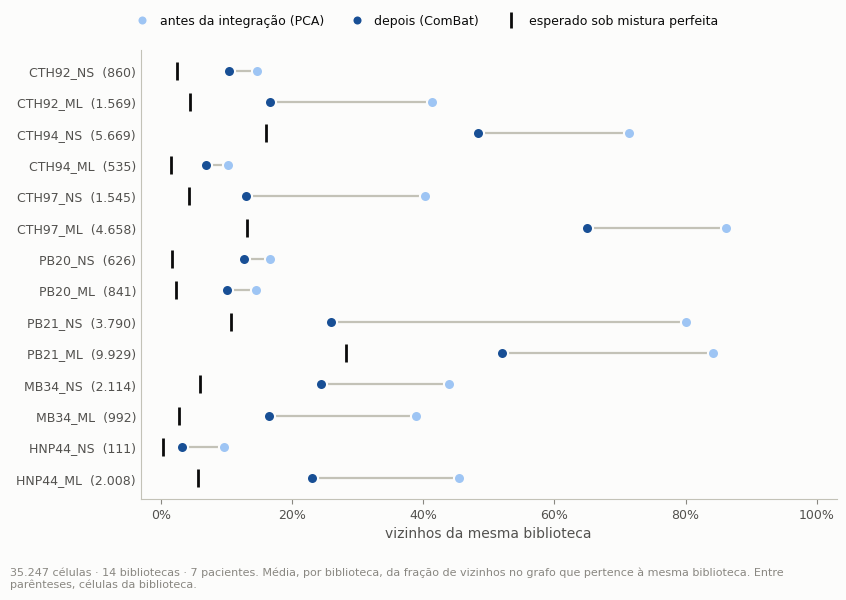

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 5.6))
y = np.arange(len(LIBS))[::-1]
antes, depois = mix[ANTES], mix[DEPOIS]
for yi, l in zip(y, LIBS):
    ax.plot([antes[l], depois[l]], [yi, yi], color=INK["axis"], lw=1.6, zorder=1, solid_capstyle="round")
    ax.plot(esperado[l], yi, marker="|", ms=13, mew=2, color=INK["primary"], zorder=2, ls="")
    ax.plot(antes[l], yi, "o", ms=8, mfc=plotting.OLD_NEW_COLORS["antiga"], mec=INK["surface"], mew=1.5, zorder=3)
    ax.plot(depois[l], yi, "o", ms=8, mfc=plotting.OLD_NEW_COLORS["nova"], mec=INK["surface"], mew=1.5, zorder=4)
ax.set_yticks(y)
ax.set_yticklabels([f"{l}  ({F.n(n_lib[l])})" for l in LIBS])
ax.set_xlim(-0.03, 1.03)
plotting.percent(ax, "x")
ax.set_xlabel("vizinhos da mesma biblioteca")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=plotting.old_new_handles(ANTES, DEPOIS) + [
    mpl.lines.Line2D([], [], marker="|", ls="", ms=11, mew=2, color=INK["primary"], label="esperado sob mistura perfeita")],
    loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Média, por biblioteca, da fração de vizinhos no grafo que pertence "
                   "à mesma biblioteca. Entre parênteses, células da biblioteca.", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
plotting.savefig(fig, NB, "mistura_de_bibliotecas", description="Vizinhos da mesma biblioteca antes e depois da integração",
                 data=mix_tab.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

In [5]:
mb = mistura.loc[DEPOIS]
ma = mistura.loc[ANTES]
resid = (mix[DEPOIS] / esperado).sort_values(ascending=False)
print(f"vizinhos da mesma biblioteca: {F.pct(ma.iloc[0], 0)} antes → {F.pct(mb.iloc[0], 0)} depois (mediana das bibliotecas); "
      f"iLISI de pacientes {F.f(ma['iLISI de pacientes (mediana)'], 2)} → {F.f(mb['iLISI de pacientes (mediana)'], 2)} "
      f"(mistura perfeita {F.f(mb['iLISI de pacientes, mistura perfeita'], 2)})")
print(f"separação NS × ML no paciente: {F.f(ma['separação NS × ML no paciente (mediana)'], 2)} → "
      f"{F.f(mb['separação NS × ML no paciente (mediana)'], 2)}")
print("bibliotecas que continuam mais separadas (vizinhos próprios ÷ esperado): "
      + "; ".join(f"{l} {F.x(v, 1)}" for l, v in resid.head(4).items()))

vizinhos da mesma biblioteca: 41% antes → 17% depois (mediana das bibliotecas); iLISI de pacientes 1,44 → 2,57 (mistura perfeita 4,32)
separação NS × ML no paciente: 0,54 → 0,33
bibliotecas que continuam mais separadas (vizinhos próprios ÷ esperado): HNP44_NS 10,2×; PB20_NS 7,1×; MB34_ML 5,9×; CTH97_ML 4,9×


## 2. Que resolução os dados sustentam

O Leiden é estocástico e a resolução é uma escolha. Para cada resolução, o
agrupamento roda com três sementes sobre o mesmo grafo; mede-se o ARI entre
as sementes e, para cada cluster da semente 0, o Jaccard com o melhor par nas
outras sementes (≥ 0,75 = cluster que reaparece quase igual).

O ARI favorece resoluções grossas (poucos clusters grandes se reproduzem com
facilidade), então duas escalas são escolhidas:

* **grossa** — a de maior ARI médio entre sementes;
* **fina (principal)** — a de maior ARI médio entre as que dão pelo menos 10
  clusters. É a usada adiante: separa os clusters técnicos e dá a
  granularidade de que a anotação vai precisar.

In [6]:
RES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
SEEDS = (0, 1, 2)
t0 = time.time()
# cache da varredura (NVMe): só refaz se o grafo, as resoluções ou as sementes mudarem
G_ = adata.obsp["connectivities"]
chave = f"{G_.nnz}_{float(G_.sum()):.6f}_{'-'.join(map(str, RES))}_{'-'.join(map(str, SEEDS))}"
cache = config.HEAVY_OUT / NB / "leiden_sweep.parquet"
if cache.exists() and pd.read_parquet(cache, columns=["chave"])["chave"].iloc[0] == chave:
    sw = pd.read_parquet(cache).drop(columns="chave")
    sw.index = obs.index
    print("varredura do Leiden lida do cache")
else:
    sw = pl.leiden_sweep(adata, RES, seeds=SEEDS)
    io._assert_writable(cache)
    cache.parent.mkdir(parents=True, exist_ok=True)
    sw.assign(chave=chave).to_parquet(cache)
linhas, jac = [], {}
for r in RES:
    cols = [f"leiden_r{r:g}_s{s}" for s in SEEDS]
    aris = [pl.clustering_agreement(sw[a], sw[b])["ARI"] for a, b in itertools.combinations(cols, 2)]
    j = pl.cluster_stability(sw[cols[0]], [sw[c] for c in cols[1:]])
    jac[r] = j
    tam = sw[cols[0]].value_counts()
    linhas.append({"resolução": r, "clusters": int(sw[cols[0]].nunique()),
                   "clusters por semente": " / ".join(str(sw[c].nunique()) for c in cols),
                   "ARI entre sementes (média)": float(np.mean(aris)), "ARI entre sementes (mínimo)": float(np.min(aris)),
                   "clusters estáveis (Jaccard ≥ 0,75)": int((j >= 0.75).sum()),
                   "células em clusters estáveis": float(tam.reindex(j.index[j >= 0.75]).sum() / N),
                   "menor cluster": int(tam.min())})
estab = pd.DataFrame(linhas).set_index("resolução")
RES_GROSSA = float(estab["ARI entre sementes (média)"].idxmax())
finas = estab[estab["clusters"] >= 10]
RES_FINAL = float(finas["ARI entre sementes (média)"].idxmax())
io.save_table(estab, NB, "estabilidade_por_resolucao", description="Leiden por resolução: número de clusters e estabilidade entre sementes")
print(f"{len(RES) * len(SEEDS)} execuções do Leiden em {time.time() - t0:.0f} s; escala grossa: {F.f(RES_GROSSA, 1)} "
      f"({estab.loc[RES_GROSSA, 'clusters']} clusters); escala fina (principal): {F.f(RES_FINAL, 1)} "
      f"({estab.loc[RES_FINAL, 'clusters']} clusters); resolução do original (0,5): ARI {F.f(estab.loc[0.5, 'ARI entre sementes (média)'], 2)}")
estab.round(3)

24 execuções do Leiden em 1368 s; escala grossa: 0,1 (4 clusters); escala fina (principal): 1,0 (19 clusters); resolução do original (0,5): ARI 0,49


,clusters,clusters por semente,ARI entre sementes (média),ARI entre sementes (mínimo),"clusters estáveis (Jaccard ≥ 0,75)",células em clusters estáveis,menor cluster
resolução,,,,,,,
0.1,4,4 / 4 / 4,0.975,0.969,4,1.000,232
0.2,6,6 / 5 / 7,0.787,0.738,5,0.937,283
0.3,8,8 / 7 / 8,0.695,0.593,5,0.870,232
0.4,9,9 / 9 / 9,0.627,0.510,6,0.782,46
0.5,12,12 / 11 / 10,0.488,0.441,4,0.189,36
0.6,14,14 / 14 / 13,0.540,0.460,5,0.278,36
0.8,17,17 / 18 / 16,0.568,0.519,7,0.182,14
1.0,19,19 / 18 / 21,0.576,0.546,8,0.211,14


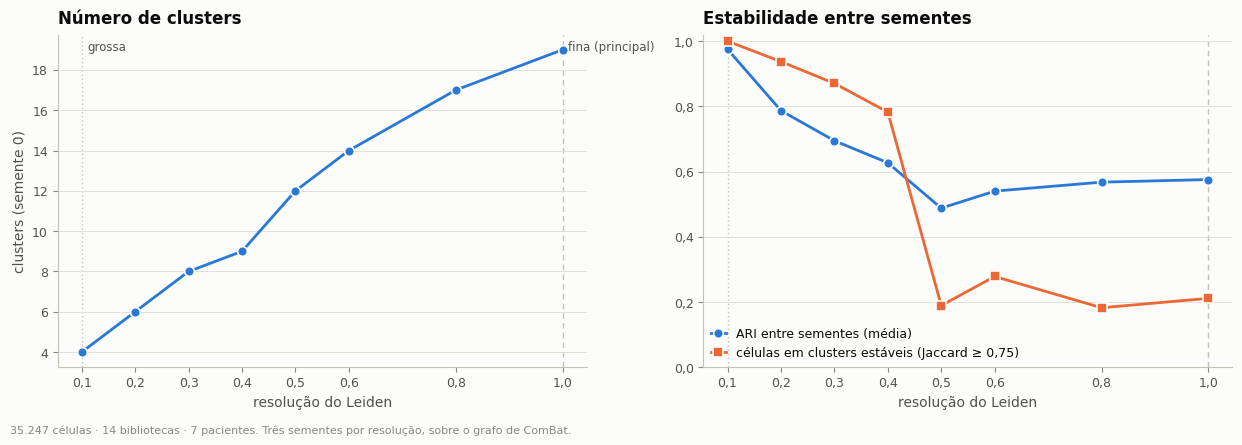

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
a1.plot(RES, estab["clusters"], "-o", color=plotting.CATEGORICAL[0], lw=2, ms=7, mec=INK["surface"], mew=1.2)
a1.set_xlabel("resolução do Leiden")
a1.set_ylabel("clusters (semente 0)")
a1.set_title("Número de clusters")
a2.plot(RES, estab["ARI entre sementes (média)"], "-o", color=plotting.CATEGORICAL[0], lw=2, ms=7, mec=INK["surface"],
        mew=1.2, label="ARI entre sementes (média)")
a2.plot(RES, estab["células em clusters estáveis"], "-s", color=plotting.CATEGORICAL[1], lw=2, ms=7, mec=INK["surface"],
        mew=1.2, label="células em clusters estáveis (Jaccard ≥ 0,75)")
a2.set_ylim(0, 1.02)
plotting.decimals(a2, "y", 1)
a2.set_xlabel("resolução do Leiden")
a2.set_title("Estabilidade entre sementes")
a2.legend(loc="lower left")
for ax in (a1, a2):
    for r_, ls_ in ((RES_GROSSA, (0, (1, 2))), (RES_FINAL, (0, (4, 3)))):
        ax.axvline(r_, color=INK["axis"], lw=1, ls=ls_, zorder=0)
    ax.set_xticks(RES)
    plotting.decimals(ax, "x", 1)
for r_, nome in ((RES_GROSSA, "grossa"), (RES_FINAL, "fina (principal)")):
    a1.annotate(nome, (r_, a1.get_ylim()[1]), xytext=(4, -4), textcoords="offset points", va="top",
                fontsize=8.5, color=INK["secondary"])
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Três sementes por resolução, sobre o grafo de {METODO}.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "resolucao", description="Número de clusters e estabilidade por resolução do Leiden",
                 data=estab.reset_index(), data_index=False)
plt.show()

## 3. Os clusters na resolução escolhida

In [8]:
cl = pd.Series(sw[f"leiden_r{RES_FINAL:g}_s0"].to_numpy(), index=obs.index)
CL = sorted(cl.unique(), key=int)
j_final = jac[RES_FINAL].reindex(CL)
share_pat = pl.share_within_group(obs.assign(cl=cl.to_numpy()), "cl", "patient", PATS)
share_lib = pl.share_within_group(obs.assign(cl=cl.to_numpy()), "cl", "library_id", LIBS)
ne_pat = pl.effective_number(share_pat).reindex(CL)
ct_pat = pd.crosstab(cl, obs["patient"].astype(str)).reindex(index=CL, columns=PATS)
bp = _bool(obs["baixa_profundidade"])
so = _bool(obs["so_no_padrao"])
g = obs.groupby(cl.to_numpy())
tab = pd.DataFrame({
    "células": cl.value_counts().reindex(CL),
    "estabilidade (Jaccard)": j_final,
    "nº efetivo de pacientes": ne_pat,
    "paciente dominante": ct_pat.idxmax(axis=1),
    "fração do paciente dominante": ct_pat.max(axis=1) / ct_pat.sum(axis=1),
    "UMIs medianos": g["total_counts"].median().reindex(CL),
    "genes medianos": g["n_genes_by_counts"].median().reindex(CL),
    "% MT mediana": g["pct_counts_mt"].median().reindex(CL),
    "baixa profundidade": pd.Series(bp, index=obs.index).groupby(cl).mean().reindex(CL),
    "do Cell Ranger que o MAD descartaria": pd.Series(so, index=obs.index).groupby(cl).mean().reindex(CL),
    "marcadores T (mediana)": g["frac_T"].median().reindex(CL),
    "marcadores B (mediana)": g["frac_B"].median().reindex(CL),
    "marcadores mieloides (mediana)": g["frac_mieloide"].median().reindex(CL),
})
motivo = []
for c in CL:
    r = tab.loc[c]
    m = []
    if r["baixa profundidade"] > 0.3:
        m.append(f"{F.pct(r['baixa profundidade'], 0)} de baixa profundidade")
    if r["UMIs medianos"] < 0.25 * np.median(umis):
        m.append(f"baixo conteúdo de RNA (mediana de {F.n(r['UMIs medianos'])} UMIs)")
    if r["marcadores T (mediana)"] < 0.001 and (r["marcadores B (mediana)"] > 0.001 or r["marcadores mieloides (mediana)"] > 0.001):
        m.append("não-T (marcadores de B ou mieloides)")
    if r["nº efetivo de pacientes"] < 2 and r["fração do paciente dominante"] > 0.5:
        m.append(f"de um paciente só ({r['paciente dominante']})")
    motivo.append("; ".join(m))
tab["marca"] = motivo
tab["técnico"] = tab["marca"].str.contains("baixa profundidade|não-T|baixo conteúdo")
io.save_table(tab, NB, "clusters", description="Clusters na resolução escolhida: estabilidade, composição, QC e linhagem")
print(f"resolução {F.f(RES_FINAL, 1)}: {len(CL)} clusters; técnicos: "
      + (", ".join(f"{c} ({tab.loc[c, 'marca']})" for c in CL if tab.loc[c, "técnico"]) or "nenhum"))
tab.round(3)

resolução 1,0: 19 clusters; técnicos: 7 (baixo conteúdo de RNA (mediana de 1.353 UMIs)), 11 (60% de baixa profundidade; baixo conteúdo de RNA (mediana de 422 UMIs)), 14 (não-T (marcadores de B ou mieloides)), 15 (não-T (marcadores de B ou mieloides))


,células,estabilidade (Jaccard),nº efetivo de pacientes,paciente dominante,fração do paciente dominante,UMIs medianos,genes medianos,% MT mediana,baixa profundidade,do Cell Ranger que o MAD descartaria,marcadores T (mediana),marcadores B (mediana),marcadores mieloides (mediana),marca,técnico
0,6940,0.613,6.592,PB21,0.476,11016.5,3294.0,2.836,0.000,0.005,0.002,0.000,0.000,,False
1,4968,0.495,6.511,PB21,0.410,9746.0,3056.5,3.501,0.000,0.009,0.002,0.000,0.000,,False
2,4415,0.744,6.275,PB21,0.564,8343.0,2422.0,3.565,0.001,0.019,0.003,0.000,0.000,,False
3,3086,0.482,6.722,PB21,0.360,10881.0,3322.5,2.839,0.000,0.005,0.002,0.000,0.000,,False
4,2798,0.537,3.354,CTH97,0.559,6302.0,1949.5,2.710,0.001,0.005,0.003,0.000,0.000,,False
5,2696,0.799,4.996,PB21,0.406,6811.0,1892.5,2.798,0.004,0.121,0.003,0.000,0.000,,False
6,2159,0.582,4.676,CTH94,0.425,11742.0,3507.0,3.358,0.000,0.008,0.003,0.000,0.000,,False
7,1855,0.407,3.759,CTH97,0.509,1353.0,748.0,3.363,0.102,0.127,0.002,0.000,0.000,baixo conteúdo de RNA (mediana de 1.353 UMIs),True
8,1733,0.929,6.334,PB21,0.504,7991.0,2782.0,2.936,0.001,0.021,0.003,0.000,0.000,,False
9,1321,0.904,5.285,CTH94,0.321,8004.0,3013.0,3.458,0.001,0.030,0.003,0.000,0.000,,False


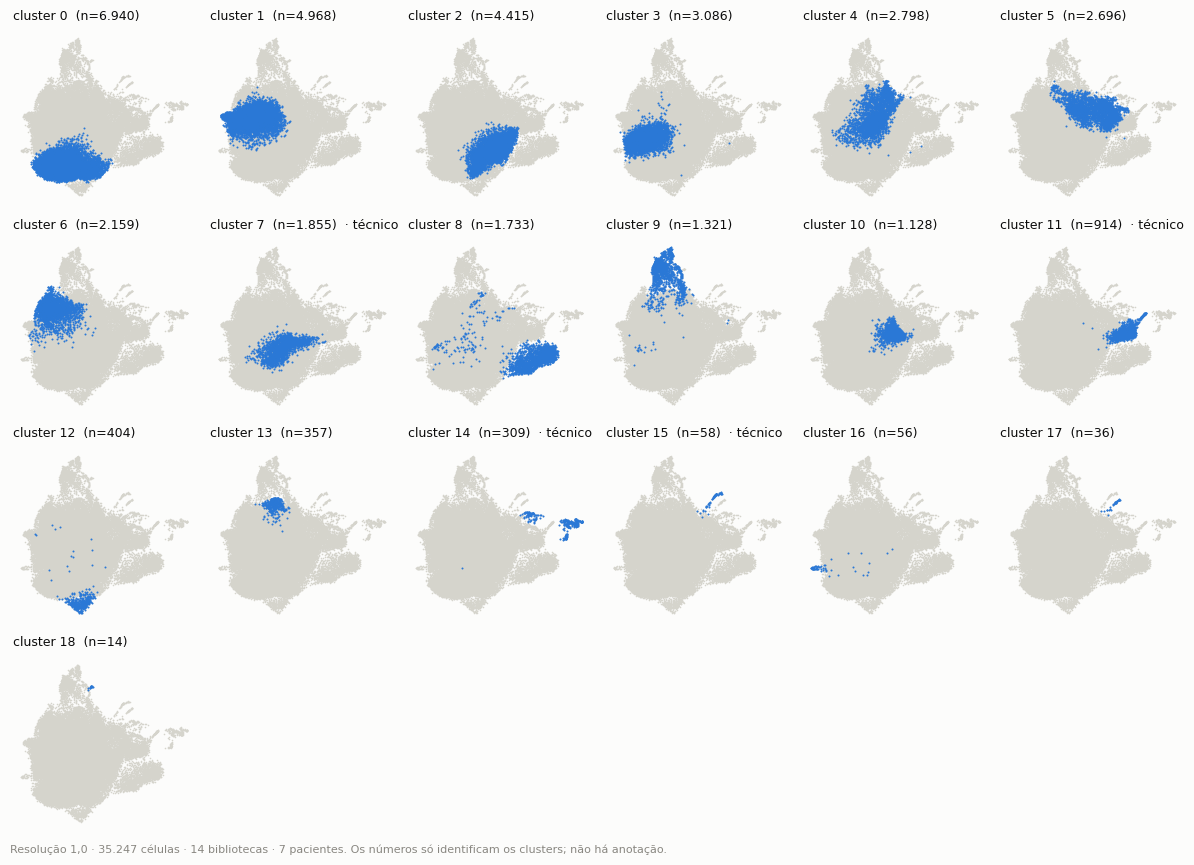

In [9]:
um = adata.obsm["X_umap"]
fig = plotting.umap_highlight_grid(um, cl.to_numpy(), order=CL, ncols=6, panel=2.0, s=1.3,
                                   title_fmt=lambda gname, n: f"cluster {gname}  (n={F.n(n)})"
                                   + ("  · técnico" if tab.loc[gname, "técnico"] else ""))
plotting.note(fig, f"Resolução {F.f(RES_FINAL, 1)} · {F.n(N)} células · {plotting.N_DESIGN}. Os números só identificam os "
                   "clusters; não há anotação.", y=0.0)
plotting.savefig(fig, NB, "umap_por_cluster", description="UMAP com cada cluster em destaque",
                 data=tab[["células", "estabilidade (Jaccard)", "marca"]].rename_axis("cluster").reset_index(), data_index=False)
plt.show()

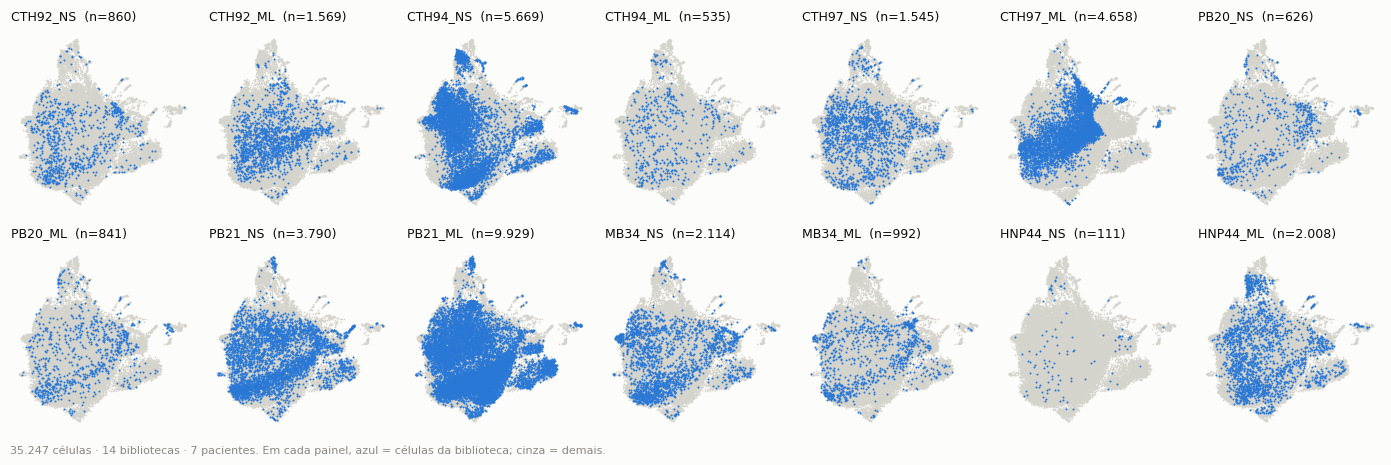

In [10]:
fig = plotting.umap_highlight_grid(um, lib_arr, order=LIBS, ncols=7, panel=2.0, s=1.3)
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Em cada painel, azul = células da biblioteca; cinza = demais.", y=0.0)
plotting.savefig(fig, NB, "umap_por_biblioteca", description="UMAP com cada biblioteca em destaque",
                 data=n_lib.rename("células").rename_axis("library_id").reset_index(), data_index=False)
plt.show()

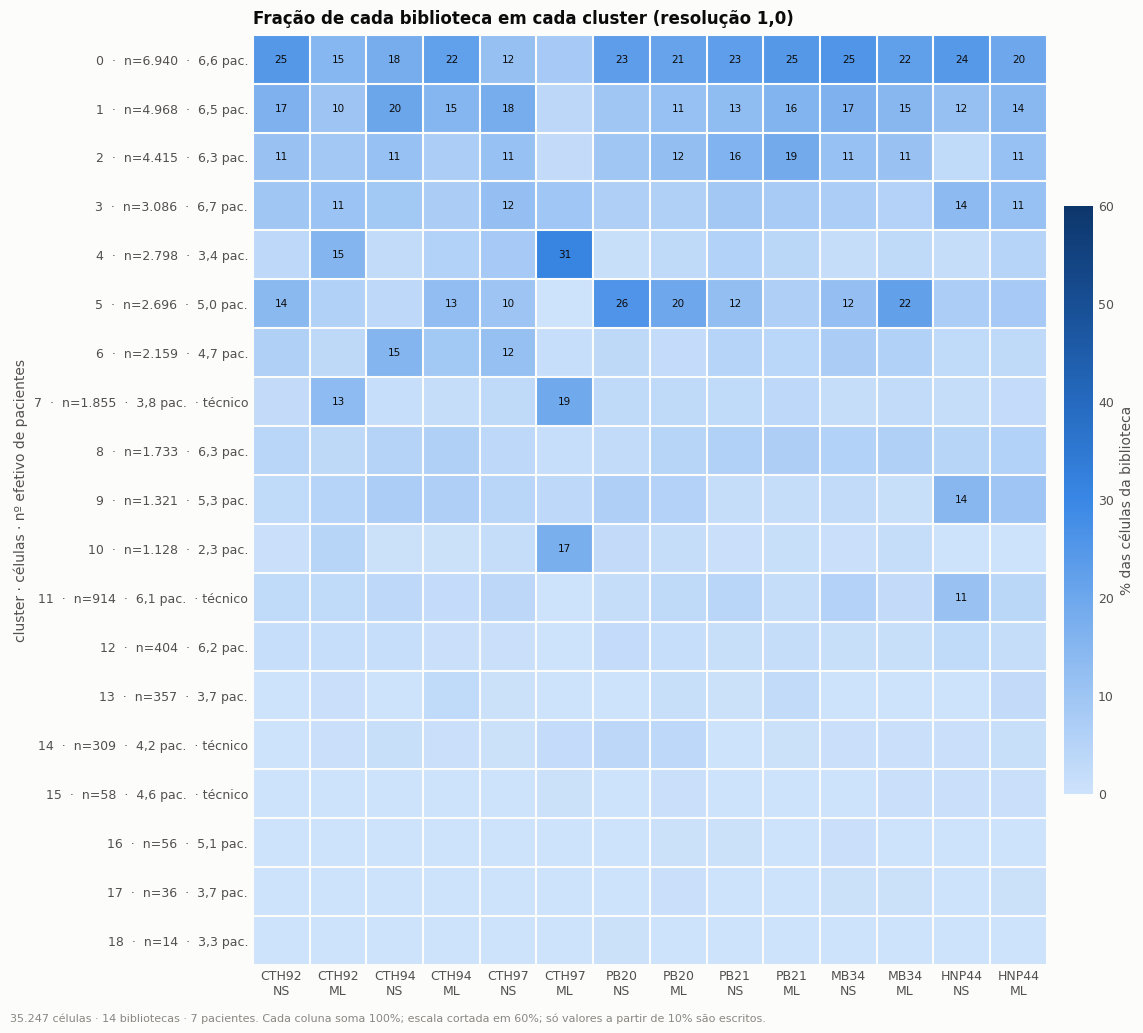

In [11]:
fig, ax = plt.subplots(figsize=(11.5, 0.42 * len(CL) + 2.2))
m = share_lib.reindex(CL) * 100
m.index = [f"{c}  ·  n={F.n(tab.loc[c, 'células'])}  ·  {F.f(tab.loc[c, 'nº efetivo de pacientes'], 1)} pac."
           + ("  · técnico" if tab.loc[c, "técnico"] else "") for c in CL]
m.columns = [f"{l.split('_')[0]}\n{l.split('_')[1]}" for l in LIBS]
plotting.heatmap(ax, m, vmin=0, vmax=60, fmt=".0f", annotate_above=10, cbar_label="% das células da biblioteca", xrotation=0)
ax.set_ylabel("cluster · células · nº efetivo de pacientes")
ax.set_title(f"Fração de cada biblioteca em cada cluster (resolução {F.f(RES_FINAL, 1)})")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Cada coluna soma 100%; escala cortada em 60%; só valores a partir "
                   "de 10% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "composicao", description="Fração das células de cada biblioteca em cada cluster",
                 data=share_lib.reindex(CL).rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 4. Profundidade dentro de cada biblioteca

In [12]:
eta = pl.eta_squared_within(np.log10(umis), cl.to_numpy(), lib_arr)
nt = ~cl.map(tab["técnico"]).to_numpy().astype(bool)
eta_nt = pl.eta_squared_within(np.log10(umis[nt]), cl.to_numpy()[nt], lib_arr[nt])
grossa = sw[f"leiden_r{RES_GROSSA:g}_s0"].to_numpy()
eta_g = pl.eta_squared_within(np.log10(umis), grossa, lib_arr)
print(f"variância de log10(UMIs) explicada pelo cluster, dentro de cada biblioteca (mediana): escala fina {F.f(eta.median(), 2)}; "
      f"escala fina sem os clusters técnicos {F.f(eta_nt.median(), 2)}; escala grossa {F.f(eta_g.median(), 2)} "
      f"(V3 de A05: 0,22; processamento original, V1: 0,57)")
io.save_table(pd.DataFrame({"escala fina": eta, "escala fina sem técnicos": eta_nt, "escala grossa": eta_g}).rename_axis("library_id"),
              NB, "profundidade_eta2", description="Fração da variância de log10(UMIs) explicada pelo cluster, por biblioteca")

variância de log10(UMIs) explicada pelo cluster, dentro de cada biblioteca (mediana): escala fina 0,59; escala fina sem os clusters técnicos 0,22; escala grossa 0,00 (V3 de A05: 0,22; processamento original, V1: 0,57)


PosixPath('/mnt/SATA/singleCellTaru/resultsReseq/tables/P08_clusterizacao/profundidade_eta2.csv')

## 5. Citocinas por cluster

Contagens corrigidas pelo SoupX (`layers["counts"]`). Positividade com
≥ 1 UMI e, mais conservadora, ≥ 2 UMIs.

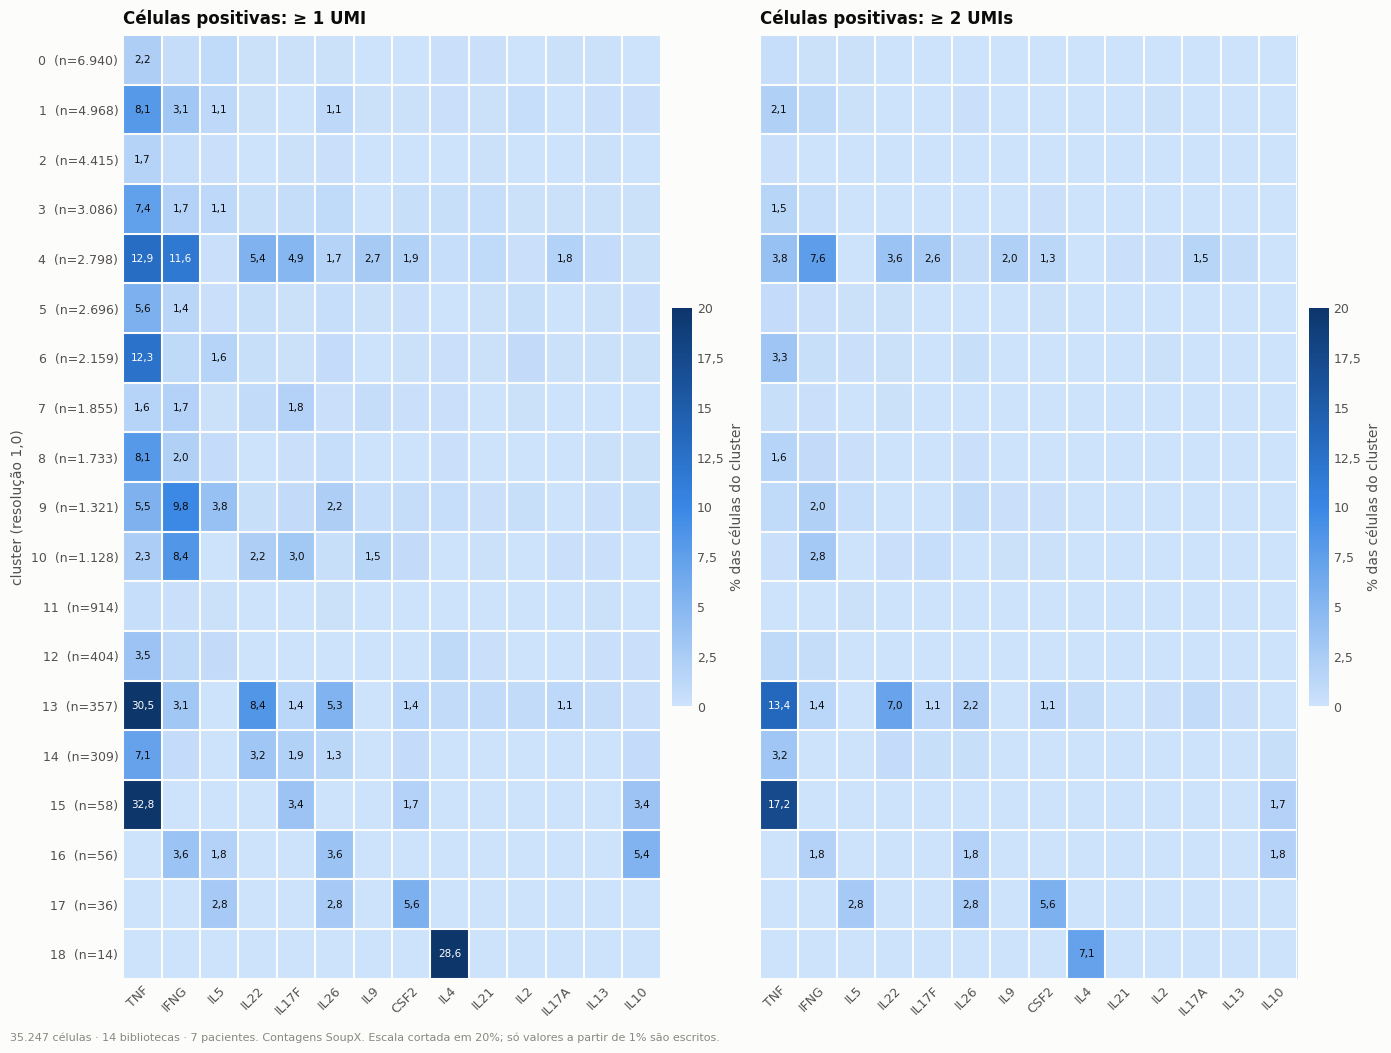

In [13]:
CYT = [gname for gname in config.CYTOKINES if gname in adata.var_names]
C = adata[:, CYT].layers["counts"]
C = pd.DataFrame(C.toarray() if sp.issparse(C) else C, index=obs.index, columns=CYT)
pos1 = (C >= 1).groupby(cl).mean().reindex(CL) * 100
pos2 = (C >= 2).groupby(cl).mean().reindex(CL) * 100
io.save_table(pos1, NB, "citocinas_por_cluster_1umi", description="% de células positivas (≥ 1 UMI) por cluster")
io.save_table(pos2, NB, "citocinas_por_cluster_2umis", description="% de células positivas (≥ 2 UMIs) por cluster")
ordem_g = (C >= 1).sum().sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(CL) + 2.4), sharey=True)
for ax, (nome, m) in zip(axes, [("≥ 1 UMI", pos1), ("≥ 2 UMIs", pos2)]):
    mm = m[ordem_g].copy()
    mm.index = [f"{c}  (n={F.n(tab.loc[c, 'células'])})" for c in CL]
    plotting.heatmap(ax, mm, vmin=0, vmax=20, fmt=".1f", annotate_above=1.0, cbar_label="% das células do cluster")
    ax.set_title(f"Células positivas: {nome}")
axes[0].set_ylabel(f"cluster (resolução {F.f(RES_FINAL, 1)})")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Contagens SoupX. Escala cortada em 20%; só valores a partir de 1% são "
                   "escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "citocinas_por_cluster", description="% de células positivas para cada citocina, por cluster",
                 data=pos1.rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 6. Estimulado × não estimulado na composição dos clusters

Para cada cluster, a fração das células de cada biblioteca que cai nele,
pareada dentro do paciente (n = 7). Descritivo: com 7 pares, o menor p exato
possível é 0,016, e nenhum cluster resiste à correção para o número de
clusters. A integração por biblioteca também aproxima as duas bibliotecas de
cada paciente (seção 1).

In [14]:
sh = share_lib.reindex(CL)
linhas = []
for c in CL:
    ns = pd.Series({p: sh.loc[c, f"{p}_NS"] for p in PATS})
    ml = pd.Series({p: sh.loc[c, f"{p}_ML"] for p in PATS})
    d = ml - ns
    pval = (float(stats.wilcoxon(ml, ns, zero_method="wilcox", alternative="two-sided", method="exact").pvalue)
            if (d != 0).all() else np.nan)
    linhas.append({"cluster": c, "mediana_NS": float(ns.median()), "mediana_ML": float(ml.median()),
                   "pacientes_ML_maior": int((d > 0).sum()), "p_wilcoxon_exato": pval})
estim = pd.DataFrame(linhas).set_index("cluster")
asc = estim["p_wilcoxon_exato"].dropna().sort_values()
estim["p_BH"] = (asc * len(asc) / np.arange(1, len(asc) + 1))[::-1].cummin()[::-1].clip(upper=1).reindex(estim.index)
io.save_table(estim, NB, "estimulo_por_cluster", description="Fração de cada biblioteca por cluster, estimulado × não estimulado (n = 7)")
estim.round(4)

,mediana_NS,mediana_ML,pacientes_ML_maior,p_wilcoxon_exato,p_BH
cluster,,,,,
0,0.2284,0.2117,2,0.2969,0.5047
1,0.1651,0.1424,3,0.3750,0.5795
2,0.1120,0.1089,3,0.9375,0.9961
3,0.0912,0.0789,1,0.0781,0.2214
4,0.0254,0.0488,6,0.0469,0.1992
5,0.1192,0.0832,3,0.8125,0.9208
6,0.0628,0.0306,1,0.0312,0.1992
7,0.0233,0.0297,6,0.0312,0.1992
8,0.0450,0.0553,5,0.6875,0.9208


## 7. Rótulos

In [15]:
rot = pd.DataFrame({"cell_key": obs["cell_key"].to_numpy(), "library_id": lib_arr,
                    "leiden_final": cl.to_numpy(), "leiden_grossa": sw[f"leiden_r{RES_GROSSA:g}_s0"].to_numpy(),
                    "cluster_tecnico": cl.map(tab["técnico"]).to_numpy()})
for r in RES:
    rot[f"leiden_r{r:g}"] = sw[f"leiden_r{r:g}_s0"].to_numpy()
rot.attrs["resolucao_final"] = RES_FINAL
io.save_data(rot, NB, "clusters",
             description=f"Rótulos do Leiden por resolução (semente 0), final (resolução {RES_FINAL:g}) e grossa "
                         f"(resolução {RES_GROSSA:g}) do objeto principal; chave cell_key")
gros = pd.crosstab(rot["leiden_final"], rot["leiden_grossa"]).reindex(CL)
io.save_table(gros, NB, "fina_x_grossa", description="Clusters da escala fina dentro dos da escala grossa")
print(f"{F.n(len(rot))} células; final: resolução {F.f(RES_FINAL, 1)}, {len(CL)} clusters, "
      f"{F.n(rot['cluster_tecnico'].sum())} células em clusters técnicos")

35.247 células; final: resolução 1,0, 19 clusters, 3.136 células em clusters técnicos


## Problemas encontrados

In [16]:
log.add("INFO", f"integração com {METODO} (por biblioteca)", "[VERIFICAÇÃO] a integração escolhida mistura bibliotecas e pacientes",
        evidence=f"vizinhos da mesma biblioteca {F.pct(ma.iloc[0], 0)} → {F.pct(mb.iloc[0], 0)} (mediana); iLISI de pacientes "
                 f"{F.f(ma['iLISI de pacientes (mediana)'], 2)} → {F.f(mb['iLISI de pacientes (mediana)'], 2)} "
                 f"(máximo {F.f(mb['iLISI de pacientes, mistura perfeita'], 2)}); as mais separadas depois: "
                 + ", ".join(f"{l} {F.x(v, 1)}" for l, v in resid.head(4).items()),
        impact="as bibliotecas que continuam separadas são as de perfil atípico (CTH97_ML) ou poucas células",
        recommendation="nenhuma; a escolha do método está justificada no P07")
log.add("MAJOR", f"{METODO} por biblioteca × estímulo",
        "a correção por biblioteca também aproxima as duas bibliotecas de cada paciente (estímulo e canal confundidos)",
        evidence=f"separação NS × ML no paciente {F.f(ma['separação NS × ML no paciente (mediana)'], 2)} → "
                 f"{F.f(mb['separação NS × ML no paciente (mediana)'], 2)}",
        impact="clusters próprios do estímulo ficam atenuados no espaço integrado",
        recommendation="testar o estímulo por pseudobulk pareado nas contagens, não pela composição dos clusters")
log.add("MINOR", "resolução do Leiden", "a resolução do original (0,5) está entre as menos estáveis",
        evidence=f"ARI entre sementes: 0,5 → {F.f(estab.loc[0.5, 'ARI entre sementes (média)'], 2)}; escala grossa "
                 f"{F.f(RES_GROSSA, 1)} → {F.f(estab.loc[RES_GROSSA, 'ARI entre sementes (média)'], 2)} "
                 f"({estab.loc[RES_GROSSA, 'clusters']} clusters); escala fina {F.f(RES_FINAL, 1)} → "
                 f"{F.f(estab.loc[RES_FINAL, 'ARI entre sementes (média)'], 2)} ({estab.loc[RES_FINAL, 'clusters']} clusters)",
        impact="a partição da massa central de células T é um recorte de um contínuo; só parte dos clusters é estável",
        recommendation=f"usar a escala fina ({RES_FINAL:g}) para anotar e a grossa ({RES_GROSSA:g}) como agrupamento robusto")
tec = tab[tab["técnico"]]
log.add("MINOR", f"clusters técnicos (resolução {RES_FINAL:g})", "parte dos clusters é técnica ou não-T",
        evidence="; ".join(f"cluster {c}: {F.n(r['células'])} células ({r['marca']})" for c, r in tec.iterrows()),
        impact=f"a profundidade explica {F.f(eta.median(), 2)} da variância de UMIs dentro da biblioteca com eles e "
               f"{F.f(eta_nt.median(), 2)} sem eles",
        recommendation="excluir ou marcar esses clusters antes da anotação (coluna cluster_tecnico)")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       1
MINOR       2
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,ComBat por biblioteca × estímulo,a correção por biblioteca também aproxima as duas bibliotecas de cada paciente (estímulo e canal confundidos),"separação NS × ML no paciente 0,54 → 0,33",clusters próprios do estímulo ficam atenuados no espaço integrado,"testar o estímulo por pseudobulk pareado nas contagens, não pela composição dos clusters"
MINOR,resolução do Leiden,"a resolução do original (0,5) está entre as menos estáveis","ARI entre sementes: 0,5 → 0,49; escala grossa 0,1 → 0,98 (4 clusters); escala fina 1,0 → 0,58 (19 clusters)",a partição da massa central de células T é um recorte de um contínuo; só parte dos clusters é estável,usar a escala fina (1) para anotar e a grossa (0.1) como agrupamento robusto
MINOR,clusters técnicos (resolução 1),parte dos clusters é técnica ou não-T,cluster 7: 1.855 células (baixo conteúdo de RNA (mediana de 1.353 UMIs)); cluster 11: 914 células (60% de baixa profundidade; baixo conteúdo de RNA (mediana de 422 UMIs)); cluster 14: 309 células (não-T (marcadores de B ou mieloides)); cluster 15: 58 células (não-T (marcadores de B ou mieloides)),"a profundidade explica 0,59 da variância de UMIs dentro da biblioteca com eles e 0,22 sem eles",excluir ou marcar esses clusters antes da anotação (coluna cluster_tecnico)
INFO,integração com ComBat (por biblioteca),[VERIFICAÇÃO] a integração escolhida mistura bibliotecas e pacientes,"vizinhos da mesma biblioteca 41% → 17% (mediana); iLISI de pacientes 1,44 → 2,57 (máximo 4,32); as mais separadas depois: HNP44_NS 10,2×, PB20_NS 7,1×, MB34_ML 5,9×, CTH97_ML 4,9×",as bibliotecas que continuam separadas são as de perfil atípico (CTH97_ML) ou poucas células,nenhuma; a escolha do método está justificada no P07


## Conclusão

**Integração (ComBat escalado, escolhido no P07).** Os vizinhos da mesma
biblioteca caem de 41% para 17% (mediana) e o número efetivo de pacientes na
vizinhança vai de 1,4 para 2,6 (máximo 4,3). O Harmony do P05 misturava
mais (11%; 2,9), mas apagava mais o estímulo: a separação entre as duas
bibliotecas de cada paciente vai de 0,54 para 0,33 com o ComBat, e ia para
0,22 com o Harmony. É o compromisso que o benchmark mediu e preferiu.
Continuam mais separadas as bibliotecas pequenas ou atípicas: HNP44_NS
(10× o esperado), PB20_NS (7×), MB34_ML (6×) e CTH97_ML (5×).

**Clusterização.** Pela regra do P07 antigo, a escala **grossa** é a 0,1
(4 clusters, ARI entre sementes 0,98) e a **fina (principal)** é a 1,0
(19 clusters, ARI 0,58). Entre 0,6 e 1,0 o ARI quase não muda (0,54–0,58), e
só 8 dos 19 clusters reaparecem quase iguais nas três sementes: a massa
central de células T é um contínuo, e a resolução fina é um recorte dele. A
0,2 (6 clusters, ARI 0,79) também está no arquivo (`leiden_r0.2`), como escala
intermediária.

**Clusters técnicos (resolução 1,0), 3.136 células:** 7 (1.855 células,
mediana de 1.353 UMIs), 11 (914; 60% de baixa profundidade, 422 UMIs), 14
(309, não-T) e 15 (58, não-T). Com eles, a profundidade explica 59% da
variância de UMIs dentro de cada biblioteca; sem eles, 22%. Estão marcados
em `cluster_tecnico`.

**Estímulo.** Quatro clusters têm mais células nas bibliotecas estimuladas
em 6 dos 7 pacientes (4, 7, 10 e 13); nenhum resiste à correção para o número
de clusters (BH ≥ 0,20), e o 10 é 74% de CTH97. São hipóteses para a
anotação, não resultado.

Rótulos: `dataReseq/P08_clusterizacao/clusters.parquet` (`leiden_final`,
`leiden_grossa`, `leiden_r*`, `cluster_tecnico`), unidos ao objeto principal
por `cell_key`, junto com `integracao_escolhida.h5ad` do P07 (embedding,
grafo e UMAP do ComBat).

In [17]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

24 artefatos gravados por este notebook:
                       name    kind
             mistura_resumo   table
     mistura_por_biblioteca   table
  profundidade_por_dimensao   table
 fig_mistura_de_bibliotecas  figure
 fig_mistura_de_bibliotecas   table
 estabilidade_por_resolucao   table
              fig_resolucao  figure
              fig_resolucao   table
                   clusters   table
       fig_umap_por_cluster  figure
       fig_umap_por_cluster   table
    fig_umap_por_biblioteca  figure
    fig_umap_por_biblioteca   table
             fig_composicao  figure
             fig_composicao   table
          profundidade_eta2   table
 citocinas_por_cluster_1umi   table
citocinas_por_cluster_2umis   table
  fig_citocinas_por_cluster  figure
  fig_citocinas_por_cluster   table
       estimulo_por_cluster   table
                   clusters parquet
              fina_x_grossa   table
                     issues   table
